In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib, json, shutil, zipfile, platform, warnings, html
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.signal import butter, sosfiltfilt
from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/obp_utils.py').exists()), Path.cwd())
RAW, OUT, FIG = [ROOT/p for p in ('data/raw/hitting','results/separation_bat_speed','figures/separation_bat_speed')]
for p in (RAW, OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)
AUTO_DOWNLOAD = True
SELECTED_SWING = None
SEEDS = (20261026, 20261027)
ALPHAS = (.1, 1., 10., 100., 1000.)
BOOTSTRAPS = 2000
GROUP = ['user','session','hitter_side']
EVENTS = ['fp_10_time','fp_100_time','contact_time']
ANGLE_COLS = ['pelvis_angle_z','torso_angle_z','torso_pelvis_angle_z']
RATE_COLS = ['pelvis_angular_velocity_z','torso_angular_velocity_z']
TARGETS = {'peak_speed':'bat_speed_mph_max_x','contact_speed':'bat_speed_mph_contact_x','blast_speed':'blast_bat_speed_mph_x'}
CONTROLS = ['height_m','mass_kg','bat_weight_oz','bat_length_in','left_handed']
MAGNITUDE = ['max_separation_deg','plant_separation_deg']
TIMING = ['peak_separation_ms_before_contact','onset_lag_ms','velocity_peak_lag_ms']
FEATURES = MAGNITUDE + TIMING
PEAKS = ['pelvis_peak_dps','torso_peak_dps']
plt.style.use('seaborn-v0_8-whitegrid')
print('Study 20 | Pelvis–Torso Separation Magnitude, Timing & Bat Speed')
print('Primary separation: pelvis axial angle minus torso axial angle; positive means pelvis leads.')
print('This axial-angle difference is a proxy, not identical to the published relative torso–pelvis rotation.')
print('Primary outcome: published maximum resultant bat speed; its exact peak-search interval is not established here.')
print('Contact and Blast speed are separate outcomes. All findings are observational.')
display(HTML('<div style="border-bottom:3px solid #173f5f;padding:8px 0 18px"><h1 style="margin-bottom:6px">Pelvis–Torso Separation & Bat Speed</h1><p style="font-size:18px;margin-top:0">Magnitude, timing and the distinction between within-session associations and held-out prediction</p><p><b>Question:</b> Do separation magnitude and timing relate to bat speed, and does the relationship persist across measurement definitions, sensors and segment rotation rates?</p><p>OpenBiomechanics Dataset v1 · Study 20 · Reproducible retrospective analysis</p><p>Run all cells to rebuild measurements, model comparisons and the final evidence summary. The closing section provides the consolidated conclusions; supporting analyses remain available below and in the generated HTML report.</p></div>'))

Study 20 | Pelvis–Torso Separation Magnitude, Timing & Bat Speed
Primary separation: pelvis axial angle minus torso axial angle; positive means pelvis leads.
This axial-angle difference is a proxy, not identical to the published relative torso–pelvis rotation.
Primary outcome: published maximum resultant bat speed; its exact peak-search interval is not established here.
Contact and Blast speed are separate outcomes. All findings are observational.


In [2]:
display(HTML('<h2>1. Inputs and cohort</h2>'))
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def download(url, path):
    if not AUTO_DOWNLOAD:
        raise FileNotFoundError(str(path))
    print('Downloading', path.name, flush=True)
    tmp = path.with_suffix(path.suffix+'.part')
    urlretrieve(url, tmp)
    tmp.replace(path)

ARCHIVES = {'joint_angles':'98a405c5c4a27c1a599d3e30b39a3087180cc4d4bb69faf62204a1c06881be95',
            'joint_velos':'3822dbce30988bc554ee533e5ccc12a5a3e92a53e185fdcb1cc8ad218dd464e4'}
BASE = 'https://github.com/drivelineresearch/openbiomechanics/releases/download/dataset-v1/'
CSV_BASE = 'https://raw.githubusercontent.com/drivelineresearch/openbiomechanics/dataset-v1/baseball_hitting/data/'
for name, digest in ARCHIVES.items():
    target = RAW/(name+'.csv')
    if not target.exists():
        archive = RAW/('hitting_'+name+'.zip')
        if not archive.exists():
            download(BASE+archive.name, archive)
        if sha256(archive) != digest:
            raise ValueError('Archive checksum mismatch: '+name)
        with zipfile.ZipFile(archive) as z:
            members = [n for n in z.namelist() if Path(n).name == target.name]
            if len(members) != 1:
                raise ValueError('Ambiguous archive: '+name)
            with z.open(members[0]) as src, target.with_suffix('.part').open('wb') as dst:
                shutil.copyfileobj(src,dst)
        target.with_suffix('.part').replace(target)
for name, remote in [('metadata','metadata.csv'),('poi_metrics','poi/poi_metrics.csv')]:
    if not (RAW/(name+'.csv')).exists():
        download(CSV_BASE+remote, RAW/(name+'.csv'))

def keys_ok(df, keys, name):
    if df[keys].isna().any().any() or df.duplicated(keys).any():
        raise ValueError('Missing/duplicate keys: '+name)

angles = pd.read_csv(RAW/'joint_angles.csv', usecols=['session_swing','time']+EVENTS+ANGLE_COLS, dtype={'session_swing':str})
velos = pd.read_csv(RAW/'joint_velos.csv', usecols=['session_swing','time']+EVENTS+RATE_COLS, dtype={'session_swing':str})
metadata = pd.read_csv(RAW/'metadata.csv', dtype={'session_swing':str,'user':str,'session':str})
poi = pd.read_csv(RAW/'poi_metrics.csv', dtype={'session_swing':str})
for name, df, keys in [('metadata',metadata,['session_swing']),('POI',poi,['session_swing']),('angles',angles,['session_swing','time']),('velos',velos,['session_swing','time'])]:
    keys_ok(df,keys,name)
if metadata[GROUP].isna().any().any() or not metadata.hitter_side.isin(['L','R']).all():
    raise ValueError('Invalid hitter identity or batting side')
base = metadata[['session_swing']+GROUP+['session_height_in','session_mass_lbs','bat_weight_oz','bat_length_in']].merge(
    poi[['session_swing']+list(TARGETS.values())+['x_factor_fp_z']], on='session_swing', how='left', validate='one_to_one')
base['height_m'] = base.session_height_in*.0254
base['mass_kg'] = base.session_mass_lbs*.45359237
base['left_handed'] = base.hitter_side.eq('L').astype(float)
for col in CONTROLS+list(TARGETS.values())+['x_factor_fp_z']:
    base[col] = pd.to_numeric(base[col],errors='coerce')
base[list(TARGETS.values())] = base[list(TARGETS.values())].where(base[list(TARGETS.values())]>0)
base[CONTROLS[:-1]] = base[CONTROLS[:-1]].where(base[CONTROLS[:-1]]>0)
ag = {str(k):g.sort_values('time') for k,g in angles.groupby('session_swing',sort=False)}
vg = {str(k):g.sort_values('time') for k,g in velos.groupby('session_swing',sort=False)}
print(f'{len(base)} metadata swings; {base.user.nunique()} hitters')

677 metadata swings; 98 hitters


In [3]:
display(HTML('<h2>2. Separation measurements and eligibility</h2>'))
def unwrap_deg(x):
    return np.rad2deg(np.unwrap(np.deg2rad(np.asarray(x,float))))

def signal(g, columns):
    t = g.time.to_numpy(float)
    x = g[columns].to_numpy(float)
    valid = np.isfinite(t) & np.isfinite(x).all(axis=1)
    where = np.flatnonzero(valid)
    if len(where):
        t,x = t[where[0]:where[-1]+1],x[where[0]:where[-1]+1]
    if len(t)<12 or not np.isfinite(t).all() or not np.isfinite(x).all() or np.any(np.diff(t)<=0):
        raise ValueError('invalid or missing signal')
    if not np.allclose(np.diff(t),np.median(np.diff(t)),rtol=.05,atol=1e-6):
        raise ValueError('irregular sampling')
    return t,x

def events(g):
    e = g[EVENTS].to_numpy(float)
    if not np.isfinite(e).all() or not np.allclose(e,e[0],rtol=0,atol=1e-8):
        raise ValueError('missing or inconsistent events')
    ffc,plant,contact = e[0]
    if not ffc<=plant<contact:
        raise ValueError('event chronology')
    return ffc,plant,contact

def window(t,x,start,end):
    if not t[0]<=start<end<=t[-1]:
        raise ValueError('window outside recording')
    q = np.r_[start,t[(t>start)&(t<end)],end]
    if end-start<2*np.median(np.diff(t)):
        raise ValueError('window too short')
    return q,np.interp(q,t,x)

def precontact_filter(t,x,contact,cutoff):
    if cutoff is None:
        return x
    q,y = window(t,x,t[0],contact)
    dt = np.median(np.diff(t))
    u = np.arange(t[0],contact+dt/2,dt)
    u = u[u<=contact]
    y = np.interp(u,q,y)
    sos = butter(4,cutoff,fs=1/dt,output='sos')
    z = sosfiltfilt(sos,y)
    return np.interp(t,u,z)

def onset(t,v,start,end,floor=60.,fraction=.15,sustain=.010):
    q,y = window(t,v,start,end)
    peak = float(y.max())
    threshold = max(floor,fraction*peak)
    if peak<=threshold:
        return np.nan,False
    mask = y>=threshold
    for i in range(len(q)):
        if mask[i]:
            j = i
            while j+1<len(q) and mask[j+1]:
                j += 1
            if q[j]-q[i]>=sustain:
                return (np.nan,True) if i==0 else (float(q[i]),False)
    return np.nan,False

def extract(a,v,lookback=.150,floor=60.,fraction=.15,cutoff=None,definition='axial_difference'):
    ta,aa = signal(a,ANGLE_COLS)
    tv,vv = signal(v,RATE_COLS)
    ffc,plant,contact = events(a)
    if not np.allclose(events(v),[ffc,plant,contact],rtol=0,atol=1e-6):
        raise ValueError('angle/velocity event disagreement')
    if contact-plant<2*max(np.median(np.diff(ta)),np.median(np.diff(tv))):
        raise ValueError('postplant interval too short')
    start = ffc-lookback
    if min(ta[-1],tv[-1])<contact or max(ta[0],tv[0])>start:
        raise ValueError('insufficient precontact coverage')
    p,t,r = [unwrap_deg(aa[:,i]) for i in range(3)]
    difference = unwrap_deg((p-t+180)%360-180)
    sep = difference if definition=='axial_difference' else -r
    sep = precontact_filter(ta,sep,contact,cutoff)
    vp,vt = [precontact_filter(tv,vv[:,i],contact,cutoff) for i in range(2)]
    q,s = window(ta,sep,start,contact)
    imax = int(np.argmax(s))
    peak_time = float(q[imax])
    out = {'max_separation_deg':float(s[imax]),'plant_separation_deg':float(np.interp(plant,ta,sep)),
           'contact_separation_deg':float(s[-1]),'peak_separation_ms_before_contact':1000*(contact-peak_time),
           'peak_separation_pct_postplant':100*(peak_time-plant)/(contact-plant),
           'separation_closure_deg':float(s[imax]-s[-1]),'peak_at_window_boundary':imax in (0,len(q)-1),
           'plant_to_contact_ms':1000*(contact-plant),'ffc_time':ffc,'plant_time':plant,'contact_time':contact,
           'axial_difference_at_plant_deg':float(np.interp(plant,ta,difference)),
           'relative_at_plant_deg':float(np.interp(plant,ta,-r)),
           'angle_rate_rmse_dps':float(np.sqrt(np.mean((np.interp(q,tv,vp-vt)-np.interp(q,ta,np.gradient(difference,ta)))**2)))}
    onsets,peaks = [],[]
    for name,rate in [('pelvis',vp),('torso',vt)]:
        qt,rv = window(tv,rate,plant,contact)
        ip = int(np.argmax(rv))
        pk = float(qt[ip])
        ot,censored = onset(tv,rate,start,pk,floor,fraction) if pk>start else (np.nan,False)
        out[name+'_onset_censored'] = censored
        out[name+'_onset_missing'] = not np.isfinite(ot)
        out[name+'_peak_dps'] = float(rv[ip])
        onsets.append(ot)
        peaks.append(pk)
    out['onset_lag_ms'] = 1000*(onsets[1]-onsets[0])
    out['velocity_peak_lag_ms'] = 1000*(peaks[1]-peaks[0])
    u = np.linspace(plant,contact,101)
    trace = {'pct':np.linspace(0,100,101),'separation':np.interp(u,ta,sep),
             'pelvis_rate':np.interp(u,tv,vp),'torso_rate':np.interp(u,tv,vt),
             'ms':1000*(q-contact),'full_separation':s,'pelvis_onset':onsets[0],'torso_onset':onsets[1]}
    return out,trace

def measure(**settings):
    rows,audit,traces = [],[],{}
    for sid in base.session_swing:
        try:
            if sid not in ag or sid not in vg:
                raise ValueError('missing signal table')
            row,trace = extract(ag[sid],vg[sid],**settings)
            rows.append({'session_swing':sid,**row})
            traces[sid] = trace
            audit.append({'session_swing':sid,'status':'retained'})
        except ValueError as exc:
            audit.append({'session_swing':sid,'status':str(exc)})
    if not rows:
        raise ValueError('No valid measurements')
    return base.merge(pd.DataFrame(rows),on='session_swing',how='inner',validate='one_to_one'),pd.DataFrame(audit),traces

measurements, exclusions, traces = measure()
measurements.to_csv(OUT/'swing_measurements.csv',index=False)
exclusions.to_csv(OUT/'exclusions.csv',index=False)
display(exclusions.status.value_counts().rename('swings').to_frame())
display(measurements[['pelvis_onset_censored','torso_onset_censored','peak_at_window_boundary']].sum().rename('swings').to_frame())
print('Missing/censored onsets retain magnitude measurements but cannot enter the timing-complete models.')
print('Additional filters are sensitivity analyses; primary processed signals receive no additional smoothing.')

,swings
status,
retained,642
missing or inconsistent events,27
event chronology,8


,swings
pelvis_onset_censored,0
torso_onset_censored,1
peak_at_window_boundary,0


Missing/censored onsets retain magnitude measurements but cannot enter the timing-complete models.
Additional filters are sensitivity analyses; primary processed signals receive no additional smoothing.


In [4]:
display(HTML('<h2>3. Between-hitter and within-session associations</h2>'))
def weights(df):
    w = 1/df.groupby('user').user.transform('size').to_numpy(float)
    return w/w.mean()

def correlation(x,y):
    return float(spearmanr(x,y).statistic) if len(x)>=4 and np.ptp(x)>0 and np.ptp(y)>0 else np.nan

def cluster_interval(values,seed=20261026):
    a = np.asarray(values,float)
    a = a[np.isfinite(a)]
    if len(a)<4:
        return np.nan,np.nan
    rng = np.random.default_rng(seed)
    b = np.array([rng.choice(a,len(a),replace=True).mean() for _ in range(BOOTSTRAPS)])
    return tuple(np.quantile(b,[.025,.975]))

INFERENCE_CONTROLS = [c for c in CONTROLS if c!='bat_weight_oz']
association_rows,influence_rows,design_rows = [],[],[]
for outcome,col in TARGETS.items():
    for feature in FEATURES:
        d = measurements.replace([np.inf,-np.inf],np.nan).dropna(subset=[feature,col]+CONTROLS).copy()
        b = d.groupby('user')[[feature,col]+CONTROLS].mean().reset_index()
        if len(b)<10:
            continue
        full_x = sm.add_constant(b[[feature]+CONTROLS],has_constant='add')
        full_fit = sm.OLS(b[col],full_x).fit()
        design_rows.append({'outcome':outcome,'feature':feature,'full_control_max_leverage':float(full_fit.get_influence().hat_matrix_diag.max()),
                            'full_control_slope':full_fit.params[feature],'bat_drop_values':int((b.bat_weight_oz-b.bat_length_in).round(4).nunique())})
        x = sm.add_constant(b[[feature]+INFERENCE_CONTROLS],has_constant='add')
        fit = sm.OLS(b[col],x).fit(cov_type='HC3')
        ci = fit.conf_int().loc[feature]
        association_rows.append({'outcome':outcome,'feature':feature,'level':'between_hitters','hitters':len(b),'swings':len(d),
            'slope_mph_per_unit':fit.params[feature],'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues[feature],
            'spearman':correlation(b[feature],b[col])})
        for uid in b.user:
            other = b[b.user!=uid]
            influence_rows.append({'outcome':outcome,'feature':feature,'omitted_hitter':uid,'spearman':correlation(other[feature],other[col])})
        d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
        if d.user.nunique()<10:
            continue
        cols = [feature,col,'plant_to_contact_ms']
        centered = d[cols]-d.groupby(GROUP)[cols].transform('mean')
        x = centered[[feature,'plant_to_contact_ms']]
        fit = sm.WLS(centered[col],x,weights=weights(d)).fit(cov_type='cluster',cov_kwds={'groups':d.user},use_t=True)
        ci = fit.conf_int().loc[feature]
        association_rows.append({'outcome':outcome,'feature':feature,'level':'within_session_side','hitters':d.user.nunique(),'swings':len(d),
            'slope_mph_per_unit':fit.params[feature],'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues[feature],
            'spearman':np.nan})
joint_rows = []
for outcome,target in TARGETS.items():
    d = measurements.dropna(subset=FEATURES+[target]).copy()
    d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
    if d.user.nunique()<10:
        continue
    columns = FEATURES+[target,'plant_to_contact_ms']
    centered = d[columns]-d.groupby(GROUP)[columns].transform('mean')
    fit = sm.WLS(centered[target],centered[FEATURES+['plant_to_contact_ms']],weights=weights(d)).fit(
        cov_type='cluster',cov_kwds={'groups':d.user},use_t=True)
    for feature in FEATURES:
        ci = fit.conf_int().loc[feature]
        joint_rows.append({'outcome':outcome,'feature':feature,'slope_mph_per_unit':fit.params[feature],
                           'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues[feature],
                           'swings':len(d),'hitters':d.user.nunique()})
joint_associations = pd.DataFrame(joint_rows)
joint_associations['fdr_q'] = np.nan
for _,ix in joint_associations.groupby('outcome').groups.items():
    joint_associations.loc[ix,'fdr_q'] = multipletests(joint_associations.loc[ix,'p'],method='fdr_bh')[1]
joint_associations.to_csv(OUT/'joint_within_session_associations.csv',index=False)
associations = pd.DataFrame(association_rows)
associations['fdr_q'] = np.nan
for _,ix in associations.groupby(['outcome','level']).groups.items():
    valid = associations.loc[ix,'p'].dropna()
    associations.loc[valid.index,'fdr_q'] = multipletests(valid,method='fdr_bh')[1]
associations.to_csv(OUT/'associations.csv',index=False)
pd.DataFrame(design_rows).to_csv(OUT/'association_design_audit.csv',index=False)
pd.DataFrame(influence_rows).to_csv(OUT/'hitter_omission_correlations.csv',index=False)
profiles = measurements.groupby(GROUP).agg(swings=('session_swing','size'),**{c:(c,'mean') for c in FEATURES+list(TARGETS.values())}).reset_index()
profiles.to_csv(OUT/'hitter_session_profiles.csv',index=False)
audit = measurements[['session_swing','user','axial_difference_at_plant_deg','relative_at_plant_deg','x_factor_fp_z','angle_rate_rmse_dps']].copy()
audit['relative_vs_axial_difference_deg'] = audit.relative_at_plant_deg-audit.axial_difference_at_plant_deg
audit['relative_vs_negated_poi_deg'] = audit.relative_at_plant_deg+audit.x_factor_fp_z
audit.to_csv(OUT/'measurement_convention_audit.csv',index=False)
display(associations[associations.outcome=='peak_speed'].round(4))
print('Between-hitter slopes adjust height, mass, bat length and side. Bat weight is omitted from inference because bat-drop variation is sparse; full-control leverage and slopes are exported.')
print('Prediction models retain bat weight. Within-session slopes adjust duration, with hitter-clustered intervals.')
print('Between and within rows use separate feature-complete cohorts. Units are degrees or milliseconds, not standardized effects.')
print('Within-session inference has a limited rep count; no individual coaching response is estimated.')

,outcome,feature,level,hitters,swings,slope_mph_per_unit,ci_low,ci_high,p,spearman,fdr_q
0,peak_speed,max_separation_deg,between_hitters,97,642,0.0784,-0.0566,0.2134,0.2550,0.1120,0.4992
1,peak_speed,max_separation_deg,within_session_side,95,639,0.2579,0.1528,0.3630,0.0000,NaN,0.0000
2,peak_speed,plant_separation_deg,between_hitters,97,642,-0.0078,-0.1222,0.1065,0.8930,0.0375,0.8930
3,peak_speed,plant_separation_deg,within_session_side,95,639,0.1908,0.0919,0.2897,0.0002,NaN,0.0006
4,peak_speed,peak_separation_ms_before_contact,between_hitters,97,642,-0.0571,-0.1172,0.0029,0.0622,-0.0570,0.3111
5,peak_speed,peak_separation_ms_before_contact,within_session_side,95,639,0.0303,0.0021,0.0585,0.0354,NaN,0.0590
6,peak_speed,onset_lag_ms,between_hitters,97,641,-0.0299,-0.0865,0.0266,0.2995,0.1102,0.4992
7,peak_speed,onset_lag_ms,within_session_side,95,638,0.0100,-0.0019,0.0219,0.0998,NaN,0.1247
8,peak_speed,velocity_peak_lag_ms,between_hitters,97,642,-0.0131,-0.0605,0.0344,0.5889,0.0553,0.7361
9,peak_speed,velocity_peak_lag_ms,within_session_side,95,639,0.0073,-0.0059,0.0205,0.2768,NaN,0.2768


Between-hitter slopes adjust height, mass, bat length and side. Bat weight is omitted from inference because bat-drop variation is sparse; full-control leverage and slopes are exported.
Prediction models retain bat weight. Within-session slopes adjust duration, with hitter-clustered intervals.
Between and within rows use separate feature-complete cohorts. Units are degrees or milliseconds, not standardized effects.
Within-session inference has a limited rep count; no individual coaching response is estimated.


In [5]:
display(HTML('<h2>4. Prediction for held-out hitters</h2>'))
def folds(users,n,seed):
    unique = np.unique(np.asarray(users))
    if len(unique)<n:
        raise ValueError('Too few hitters for grouped folds')
    unique = np.random.default_rng(seed).permutation(unique)
    for group in np.array_split(unique,n):
        valid = np.flatnonzero(np.isin(users,group))
        train = np.flatnonzero(~np.isin(users,group))
        assert not set(np.asarray(users)[train]) & set(np.asarray(users)[valid])
        yield train,valid

def ridge_predict(train,test,features,target,alpha):
    w = weights(train)
    scaler = StandardScaler().fit(train[features],sample_weight=w)
    model = Ridge(alpha=alpha).fit(scaler.transform(train[features]),train[target],sample_weight=w)
    return model.predict(scaler.transform(test[features]))

def hitter_mae(df,y,p):
    return pd.Series(np.abs(np.asarray(y)-np.asarray(p)),index=df.index).groupby(df.user).mean().mean()

MODELS = {'controls':CONTROLS,'magnitude':CONTROLS+MAGNITUDE,'timing':CONTROLS+TIMING,
          'combined':CONTROLS+FEATURES,'controls_rotation':CONTROLS+PEAKS,'combined_rotation':CONTROLS+PEAKS+FEATURES}

def validate(d,target,outcome,seeds=SEEDS,label='primary'):
    predictions,tuning,fold_log = [],[],[]
    d = d.reset_index(drop=True)
    for seed in seeds:
        for fold,(itr,ite) in enumerate(folds(d.user.to_numpy(),5,seed)):
            train,test = d.iloc[itr],d.iloc[ite]
            for part,tab in [('train',train),('test',test)]:
                fold_log.extend({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'part':part,'user':u} for u in tab.user.unique())
            for model,features in MODELS.items():
                scores = []
                for alpha in ALPHAS:
                    inner_pred = np.full(len(train),np.nan)
                    for ia,ib in folds(train.user.to_numpy(),4,seed+fold+100):
                        inner_pred[ib] = ridge_predict(train.iloc[ia],train.iloc[ib],features,target,alpha)
                    scores.append(hitter_mae(train,train[target],inner_pred))
                alpha = ALPHAS[int(np.argmin(scores))]
                pred = ridge_predict(train,test,features,target,alpha)
                tuning.append({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'model':model,'alpha':alpha,'inner_hitter_mae':min(scores)})
                predictions.extend({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'model':model,'session_swing':sid,'user':uid,'observed':y,'predicted':p}
                    for sid,uid,y,p in zip(test.session_swing,test.user,test[target],pred))
            mean = np.average(train[target],weights=weights(train))
            predictions.extend({'analysis':label,'outcome':outcome,'seed':seed,'fold':fold,'model':'training_mean','session_swing':sid,'user':uid,'observed':y,'predicted':mean}
                for sid,uid,y in zip(test.session_swing,test.user,test[target]))
    return pd.DataFrame(predictions),pd.DataFrame(tuning),pd.DataFrame(fold_log)

prediction_tables,tuning_tables,fold_tables,cohorts = [],[],[],[]
for outcome,target in TARGETS.items():
    d = measurements.replace([np.inf,-np.inf],np.nan).dropna(subset=CONTROLS+FEATURES+PEAKS+[target]).copy()
    cohorts.append({'outcome':outcome,'swings':len(d),'hitters':d.user.nunique(),'eligible_magnitude_swings':int(measurements[MAGNITUDE+[target]].notna().all(axis=1).sum())})
    if d.user.nunique()<15:
        print('Skipping grouped models for',outcome,': fewer than 15 hitters')
        continue
    print('Validating',outcome,len(d),'swings;',d.user.nunique(),'hitters',flush=True)
    p,t,f = validate(d,target,outcome)
    prediction_tables.append(p)
    tuning_tables.append(t)
    fold_tables.append(f)
if not prediction_tables:
    raise ValueError('No outcome has enough timing-complete hitters for grouped validation')
predictions = pd.concat(prediction_tables,ignore_index=True)
tuning = pd.concat(tuning_tables,ignore_index=True)
fold_membership = pd.concat(fold_tables,ignore_index=True)
predictions['absolute_error'] = abs(predictions.observed-predictions.predicted)
per_hitter = predictions.groupby(['outcome','model','user']).absolute_error.mean().reset_index()
model_summary = per_hitter.groupby(['outcome','model']).absolute_error.agg(['mean','count']).reset_index().rename(columns={'mean':'hitter_mae_mph','count':'hitters'})
comparisons = []
for outcome,g in per_hitter.groupby('outcome'):
    wide = g.pivot(index='user',columns='model',values='absolute_error')
    for baseline,added in [('training_mean','controls'),('controls','magnitude'),('controls','timing'),('magnitude','combined'),('timing','combined'),('controls','combined'),('controls_rotation','combined_rotation')]:
        diff = wide[baseline]-wide[added]
        lo,hi = cluster_interval(diff)
        comparisons.append({'outcome':outcome,'baseline':baseline,'added':added,'mae_improvement_mph':diff.mean(),'ci_low':lo,'ci_high':hi,'hitters':len(diff)})
comparisons = pd.DataFrame(comparisons)
for name,df in [('heldout_predictions',predictions),('tuning',tuning),('fold_membership',fold_membership),('outcome_cohorts',pd.DataFrame(cohorts)),('model_summary',model_summary),('paired_model_comparisons',comparisons)]:
    df.to_csv(OUT/(name+'.csv'),index=False)
display(pd.DataFrame(cohorts))
display(comparisons[comparisons.outcome=='peak_speed'].round(4))
print('Positive paired improvement favors the added model. Intervals resample fixed held-out hitter errors; they do not refit models.')

Validating peak_speed 641 swings; 97 hitters
Validating contact_speed 641 swings; 97 hitters
Validating blast_speed 612 swings; 96 hitters


,outcome,swings,hitters,eligible_magnitude_swings
0,peak_speed,641,97,642
1,contact_speed,641,97,642
2,blast_speed,612,96,613


,outcome,baseline,added,mae_improvement_mph,ci_low,ci_high,hitters
14,peak_speed,training_mean,controls,0.5063,0.0572,0.9554,97
15,peak_speed,controls,magnitude,-0.0129,-0.1458,0.1240,97
16,peak_speed,controls,timing,-0.0129,-0.1012,0.0774,97
17,peak_speed,magnitude,combined,-0.0456,-0.1363,0.0488,97
18,peak_speed,timing,combined,-0.0456,-0.1595,0.0667,97
19,peak_speed,controls,combined,-0.0585,-0.1958,0.0831,97
20,peak_speed,controls_rotation,combined_rotation,0.0074,-0.1336,0.1444,97


Positive paired improvement favors the added model. Intervals resample fixed held-out hitter errors; they do not refit models.


In [6]:
display(HTML('<h2>5. Measurement-definition and event sensitivities</h2>'))
settings = {'native':{},'floor_40':{'floor':40.},'floor_80':{'floor':80.},'fraction_10':{'fraction':.10},'fraction_20':{'fraction':.20},
            'filter_8':{'cutoff':8.},'filter_12':{'cutoff':12.},'filter_16':{'cutoff':16.},
            'lookback_100':{'lookback':.100},'lookback_200':{'lookback':.200},'relative_rotation':{'definition':'relative'}}
sensitivity_tables = {'native':measurements}
sensitivity_audits = []
for label,config in settings.items():
    if label=='native':
        continue
    alt,aud,_ = measure(**config)
    sensitivity_tables[label] = alt
    sensitivity_audits.append(aud.assign(setting=label))
for label,mask in [('duration_80_200',measurements.plant_to_contact_ms.between(80,200)),
                   ('interior_separation_peak',~measurements.peak_at_window_boundary)]:
    sensitivity_tables[label] = measurements.loc[mask].copy()
def within_slope(d,column,target):
    d = d[d.groupby(GROUP).session_swing.transform('size')>=3].copy()
    if d.user.nunique()<10:
        return np.nan,np.nan,np.nan
    cols = [column,target,'plant_to_contact_ms']
    z = d[cols]-d.groupby(GROUP)[cols].transform('mean')
    fit = sm.WLS(z[target],z[[column,'plant_to_contact_ms']],weights=weights(d)).fit(
        cov_type='cluster',cov_kwds={'groups':d.user},use_t=True)
    ci = fit.conf_int().loc[column]
    return fit.params[column],ci.iloc[0],ci.iloc[1]

sensitivity_rows = []
for label,alt in sensitivity_tables.items():
    for feature in FEATURES:
        target = TARGETS['peak_speed']
        pair = measurements[['session_swing']+GROUP+['plant_to_contact_ms',feature,target]].merge(alt[['session_swing',feature]],on='session_swing',suffixes=('_primary','_alternate'),validate='one_to_one').dropna()
        a,b = feature+'_primary',feature+'_alternate'
        grouped = pair.groupby('user')[[a,b,target]].mean()
        if len(grouped)<4:
            continue
        wa,la,ha = within_slope(pair,a,target)
        wb,lb,hb = within_slope(pair,b,target)
        sensitivity_rows.append({'within_primary_slope':wa,'within_primary_ci_low':la,'within_primary_ci_high':ha,
            'within_alternate_slope':wb,'within_alternate_ci_low':lb,'within_alternate_ci_high':hb,'setting':label,'feature':feature,'retained_swings':len(alt),'matched_swings':len(pair),'matched_hitters':len(grouped),
            'median_paired_change':float((pair[b]-pair[a]).median()),'hitter_rank_agreement':correlation(grouped[a],grouped[b]),
            'primary_speed_rho_matched':correlation(grouped[a],grouped[target]),'alternate_speed_rho_matched':correlation(grouped[b],grouped[target])})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT/'matched_measurement_sensitivities.csv',index=False)
pd.concat(sensitivity_audits,ignore_index=True).to_csv(OUT/'sensitivity_exclusions.csv',index=False)
complete = CONTROLS+FEATURES+PEAKS+[TARGETS['peak_speed']]
primary_ids = set(measurements.dropna(subset=complete).session_swing)
relative_ids = set(sensitivity_tables['relative_rotation'].dropna(subset=complete).session_swing)
matched_ids = primary_ids & relative_ids
refit_scenarios = {'native_matched_relative': measurements.query('session_swing in @matched_ids').copy(),
                   'relative_rotation': sensitivity_tables['relative_rotation'].query('session_swing in @matched_ids').copy(),
                   'duration_80_200': sensitivity_tables['duration_80_200'].dropna(subset=complete).copy()}
interior = sensitivity_tables['interior_separation_peak'].dropna(subset=complete).copy()
if set(interior.session_swing)!=primary_ids:
    refit_scenarios['interior_separation_peak'] = interior
refit_predictions,refit_comparisons = [],[]
for label,d in refit_scenarios.items():
    if d.user.nunique()<15:
        continue
    print('Matched sensitivity refit:',label,len(d),'swings',flush=True)
    p,t,f = validate(d,TARGETS['peak_speed'],'peak_speed',seeds=(SEEDS[0],),label=label)
    p['absolute_error'] = abs(p.observed-p.predicted)
    refit_predictions.append(p)
    t.to_csv(OUT/('sensitivity_tuning_'+label+'.csv'),index=False)
    f.to_csv(OUT/('sensitivity_folds_'+label+'.csv'),index=False)
    w = p.groupby(['user','model']).absolute_error.mean().unstack()
    for baseline,added in [('controls','combined'),('magnitude','combined'),('controls_rotation','combined_rotation')]:
        diff = w[baseline]-w[added]
        lo,hi = cluster_interval(diff)
        refit_comparisons.append({'setting':label,'baseline':baseline,'added':added,'mae_improvement_mph':diff.mean(),'ci_low':lo,'ci_high':hi,'swings':len(d),'hitters':len(w)})
if refit_predictions:
    pd.concat(refit_predictions,ignore_index=True).to_csv(OUT/'matched_sensitivity_predictions.csv',index=False)
pd.DataFrame(refit_comparisons).to_csv(OUT/'matched_sensitivity_models.csv',index=False)
display(sensitivity[sensitivity.feature=='peak_separation_ms_before_contact'][['setting','matched_swings','matched_hitters','median_paired_change','hitter_rank_agreement','within_alternate_slope','within_alternate_ci_low','within_alternate_ci_high']].round(3))
print('Native versus relative rotation refits share swings and folds. Duration/interior screens are separate cohorts: compare added versus baseline within each screen, not raw MAE across cohorts. Refits use one CV repeat.')

Matched sensitivity refit: native_matched_relative 641 swings
Matched sensitivity refit: relative_rotation 641 swings
Matched sensitivity refit: duration_80_200 614 swings


,setting,matched_swings,matched_hitters,median_paired_change,hitter_rank_agreement,within_alternate_slope,within_alternate_ci_low,within_alternate_ci_high
2,native,642,97,0.0,1.000,0.030,0.002,0.059
7,floor_40,642,97,0.0,1.000,0.030,0.002,0.059
12,floor_80,642,97,0.0,1.000,0.030,0.002,0.059
17,fraction_10,642,97,0.0,1.000,0.030,0.002,0.059
22,fraction_20,642,97,0.0,1.000,0.030,0.002,0.059
27,filter_8,642,97,0.0,0.967,0.037,0.004,0.069
32,filter_12,642,97,0.0,0.990,0.034,0.005,0.062
37,filter_16,642,97,0.0,0.997,0.031,0.004,0.057
42,lookback_100,642,97,0.0,1.000,0.030,0.002,0.059
47,lookback_200,642,97,0.0,1.000,0.030,0.002,0.059


Native versus relative rotation refits share swings and folds. Duration/interior screens are separate cohorts: compare added versus baseline within each screen, not raw MAE across cohorts. Refits use one CV repeat.


Matched robustness audit: identical swings, session-side eligibility and hitter weights in all 12 comparisons.


,stage,swings,hitters
0,eligible motion measurements,642,97
1,common outcomes and definitions; at least thre...,610,94


,definition,outcome,slope_mph_per_degree,bootstrap_ci_low,bootstrap_ci_high,fdr_q,omission_min,omission_max,omission_sign_reversals
0,axial,peak_speed,0.2541,0.1575,0.3706,0.0001,0.2340,0.2918,0
1,axial,contact_speed,0.1978,0.0928,0.3153,0.0020,0.1758,0.2265,0
2,axial,blast_speed,0.2062,0.0632,0.3653,0.0137,0.1879,0.2318,0
3,relative,peak_speed,0.2045,0.1084,0.3454,0.0020,0.1871,0.2585,0
4,relative,contact_speed,0.1434,0.0453,0.2749,0.0137,0.1243,0.1719,0
5,relative,blast_speed,0.1711,0.0329,0.3309,0.0185,0.1568,0.1990,0


,metric,contrast,slope_difference_mph_per_degree,paired_bootstrap_ci_low,paired_bootstrap_ci_high
0,max_separation_deg,relative minus axial; peak_speed,-0.0496,-0.0810,0.0009
1,max_separation_deg,relative minus axial; contact_speed,-0.0545,-0.0908,-0.0131
2,max_separation_deg,relative minus axial; blast_speed,-0.0352,-0.0880,0.0153
3,max_separation_deg,Blast minus published peak; axial,-0.0478,-0.1894,0.0835
4,max_separation_deg,Blast minus contact; axial,0.0084,-0.1473,0.1601
5,max_separation_deg,Blast minus published peak; relative,-0.0334,-0.1795,0.0817
6,max_separation_deg,Blast minus contact; relative,0.0277,-0.1204,0.1614


Slope units: mph per degree. All regressions adjust within-session plant-to-contact duration.
Bootstrap intervals resample whole hitters 2,000 times and refit the centered regressions. Shared draws preserve paired contrasts.
FDR applies separately to six tests per magnitude metric. Paired contrasts are exploratory, without multiplicity adjustment.
Omission ranges assess influence. Stable signs do not establish causal effects, test–retest reliability or external validity.


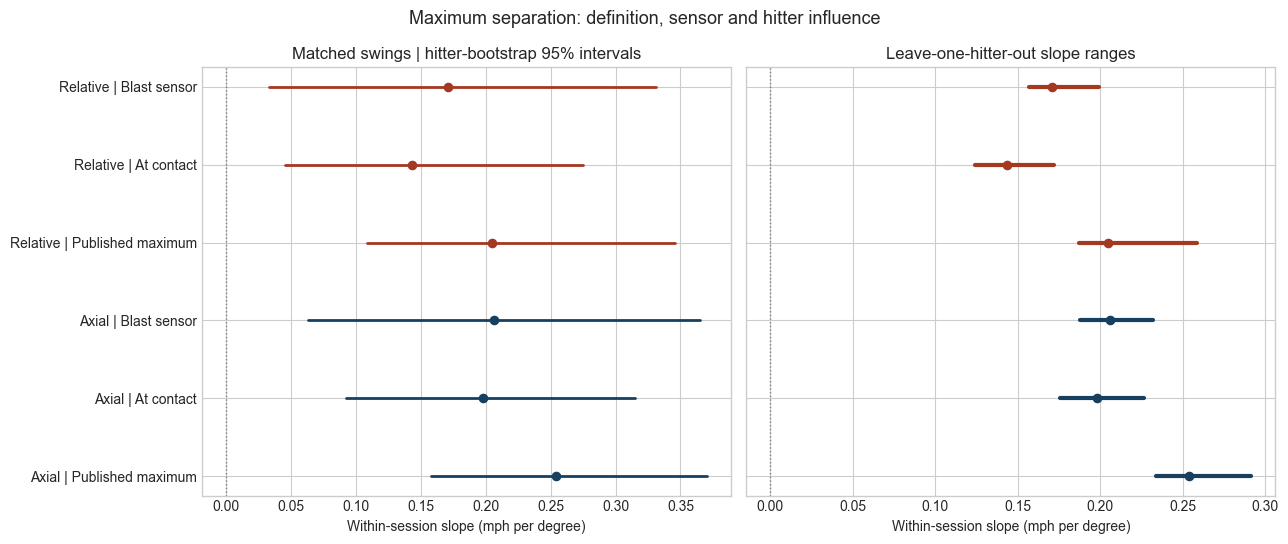

On the common cohort, maximum separation has positive within-session associations with published maximum and Blast speed under both definitions; all four hitter-bootstrap intervals are above zero. Across these four fits, 0 leave-one-hitter-out sign reversals were observed. This is an influence check, not an intervention result.
Checks passed: common cohort, complete data, equal hitter contributions, sufficient-statistic slopes equal direct WLS, and omission slopes equal direct refits.


In [7]:
display(HTML('<h2>6. Matched swings across definitions and speed measurements</h2>'))
AUDIT_SEED = 20261028
AUDIT_BOOTSTRAPS = 2000
AUDIT_METRICS = ['max_separation_deg','plant_separation_deg']
identity = ['session_swing']+GROUP
shared = measurements[identity+['plant_to_contact_ms']+list(TARGETS.values())+AUDIT_METRICS].copy()
shared = shared.rename(columns={c:'axial_'+c for c in AUDIT_METRICS})
relative = sensitivity_tables['relative_rotation'][identity+['plant_to_contact_ms']+AUDIT_METRICS].copy()
relative = relative.rename(columns={c:'relative_'+c for c in AUDIT_METRICS})
shared = shared.merge(relative,on=identity,suffixes=('','_relative'),how='inner',validate='one_to_one')
if not np.allclose(shared.plant_to_contact_ms,shared.plant_to_contact_ms_relative,rtol=0,atol=1e-8):
    raise ValueError('Separation definitions disagree on swing duration')
required = ['plant_to_contact_ms']+list(TARGETS.values())+[prefix+c for prefix in ['axial_','relative_'] for c in AUDIT_METRICS]
shared = shared.replace([np.inf,-np.inf],np.nan).dropna(subset=required).copy()
shared = shared[shared.groupby(GROUP).session_swing.transform('size')>=3].reset_index(drop=True)
if shared.user.nunique()<15:
    raise ValueError('Fewer than 15 hitters on the common sensor/definition cohort')
shared.to_csv(OUT/'robustness_matched_swings.csv',index=False)
cohort_audit = pd.DataFrame([{'stage':'eligible motion measurements','swings':len(measurements),'hitters':measurements.user.nunique()},
    {'stage':'common outcomes and definitions; at least three swings per session-side','swings':len(shared),'hitters':shared.user.nunique()}])
cohort_audit.to_csv(OUT/'robustness_cohort.csv',index=False)
users = np.array(sorted(shared.user.unique()))
uid_lookup = {u:i for i,u in enumerate(users)}
rng = np.random.default_rng(AUDIT_SEED)
resample_counts = rng.multinomial(len(users),np.full(len(users),1/len(users)),size=AUDIT_BOOTSTRAPS)
assert np.all(resample_counts.sum(axis=1)==len(users))

def sufficient_within(d,feature,target,ordered_users):
    cols = [feature,'plant_to_contact_ms',target]
    z = d[cols]-d.groupby(GROUP)[cols].transform('mean')
    x,y = z[[feature,'plant_to_contact_ms']].to_numpy(float),z[target].to_numpy(float)
    aa,bb = [],[]
    for uid in ordered_users:
        mask = d.user.eq(uid).to_numpy()
        if not mask.any():
            raise ValueError('Missing expected hitter in matched cohort')
        xi,yi = x[mask],y[mask]
        aa.append(xi.T@xi/len(xi))
        bb.append(xi.T@yi/len(xi))
    return np.array(aa),np.array(bb),x,y

robust_rows,omission_rows,bootstrap_slopes = [],[],{}
for metric in AUDIT_METRICS:
    for definition in ['axial','relative']:
        feature = definition+'_'+metric
        for outcome,target in TARGETS.items():
            aa,bb,x,y = sufficient_within(shared,feature,target,users)
            summed_a,summed_b = aa.sum(axis=0),bb.sum(axis=0)
            if np.linalg.matrix_rank(summed_a)<2:
                raise ValueError('Rank-deficient within-session design')
            coef = np.linalg.solve(summed_a,summed_b)
            fit = sm.WLS(y,x,weights=weights(shared)).fit(cov_type='cluster',cov_kwds={'groups':shared.user},use_t=True)
            np.testing.assert_allclose(coef,fit.params,rtol=1e-7,atol=1e-8)
            ba = np.einsum('bh,hij->bij',resample_counts,aa)
            by = resample_counts@bb
            boot = np.linalg.solve(ba,by[...,None])[...,0][:,0]
            key = (metric,definition,outcome)
            bootstrap_slopes[key] = boot
            lo,hi = np.quantile(boot,[.025,.975])
            omitted = []
            for i,uid in enumerate(users):
                slope = np.linalg.solve(summed_a-aa[i],summed_b-bb[i])[0]
                omitted.append(slope)
                omission_rows.append({'metric':metric,'definition':definition,'outcome':outcome,'omitted_hitter':uid,
                    'slope_mph_per_degree':slope,'change_from_full':slope-coef[0]})
            omitted = np.array(omitted)
            largest = int(np.argmax(abs(omitted-coef[0])))
            robust_rows.append({'metric':metric,'definition':definition,'outcome':outcome,'swings':len(shared),'hitters':len(users),
                'slope_mph_per_degree':coef[0],'bootstrap_ci_low':lo,'bootstrap_ci_high':hi,'cluster_p':fit.pvalues[0],
                'omission_min':omitted.min(),'omission_max':omitted.max(),
                'omission_sign_reversals':int(np.sum(np.sign(omitted)!=np.sign(coef[0]))),
                'largest_influence_hitter':users[largest],'largest_absolute_slope_change':abs(omitted[largest]-coef[0])})
            remaining = shared[shared.user.ne(users[0])].copy()
            ac,bc,xc,yc = sufficient_within(remaining,feature,target,users[1:])
            direct = sm.WLS(yc,xc,weights=weights(remaining)).fit().params[0]
            np.testing.assert_allclose(direct,np.linalg.solve(summed_a-aa[0],summed_b-bb[0])[0],rtol=1e-7,atol=1e-8)
robustness = pd.DataFrame(robust_rows)
robustness['fdr_q'] = np.nan
for metric,ix in robustness.groupby('metric').groups.items():
    robustness.loc[ix,'fdr_q'] = multipletests(robustness.loc[ix,'cluster_p'],method='fdr_bh')[1]
omissions = pd.DataFrame(omission_rows)
robustness.to_csv(OUT/'robustness_within_session_slopes.csv',index=False)
omissions.to_csv(OUT/'robustness_hitter_omissions.csv',index=False)
paired_rows = []
for metric in AUDIT_METRICS:
    contrasts = []
    for outcome in TARGETS:
        contrasts.append(((metric,'relative',outcome),(metric,'axial',outcome),'relative minus axial; '+outcome))
    for definition in ['axial','relative']:
        contrasts.extend([((metric,definition,'blast_speed'),(metric,definition,'peak_speed'),'Blast minus published peak; '+definition),
                          ((metric,definition,'blast_speed'),(metric,definition,'contact_speed'),'Blast minus contact; '+definition)])
    for first,second,label in contrasts:
        delta = bootstrap_slopes[first]-bootstrap_slopes[second]
        def point(key):
            return robustness[(robustness.metric==key[0])&(robustness.definition==key[1])&(robustness.outcome==key[2])].slope_mph_per_degree.iloc[0]
        lo,hi = np.quantile(delta,[.025,.975])
        paired_rows.append({'metric':metric,'contrast':label,'slope_difference_mph_per_degree':point(first)-point(second),
                           'paired_bootstrap_ci_low':lo,'paired_bootstrap_ci_high':hi})
paired_slope_comparisons = pd.DataFrame(paired_rows)
paired_slope_comparisons.to_csv(OUT/'robustness_paired_slope_comparisons.csv',index=False)
np.savez_compressed(OUT/'robustness_paired_bootstrap.npz',**{'__'.join(k):v for k,v in bootstrap_slopes.items()})
print('Matched robustness audit: identical swings, session-side eligibility and hitter weights in all 12 comparisons.')
display(cohort_audit)
display(robustness[robustness.metric=='max_separation_deg'][['definition','outcome','slope_mph_per_degree','bootstrap_ci_low','bootstrap_ci_high','fdr_q','omission_min','omission_max','omission_sign_reversals']].round(4))
display(paired_slope_comparisons[paired_slope_comparisons.metric=='max_separation_deg'].round(4))
print('Slope units: mph per degree. All regressions adjust within-session plant-to-contact duration.')
print('Bootstrap intervals resample whole hitters 2,000 times and refit the centered regressions. Shared draws preserve paired contrasts.')
print('FDR applies separately to six tests per magnitude metric. Paired contrasts are exploratory, without multiplicity adjustment.')
print('Omission ranges assess influence. Stable signs do not establish causal effects, test–retest reliability or external validity.')
labels = {'peak_speed':'Published maximum','contact_speed':'At contact','blast_speed':'Blast sensor'}
fig,axes = plt.subplots(1,2,figsize=(13,5.5),sharey=True)
plot = robustness[robustness.metric=='max_separation_deg'].copy().reset_index(drop=True)
ypos = np.arange(len(plot))
for i,row in plot.iterrows():
    color = '#173f5f' if row.definition=='axial' else '#a43820'
    axes[0].plot([row.bootstrap_ci_low,row.bootstrap_ci_high],[i,i],color=color,lw=2)
    axes[0].scatter(row.slope_mph_per_degree,i,color=color,s=35)
    axes[1].plot([row.omission_min,row.omission_max],[i,i],color=color,lw=3)
    axes[1].scatter(row.slope_mph_per_degree,i,color=color,s=35)
axes[0].set_yticks(ypos,[row.definition.title()+' | '+labels[row.outcome] for _,row in plot.iterrows()])
axes[0].set_title('Matched swings | hitter-bootstrap 95% intervals')
axes[1].set_title('Leave-one-hitter-out slope ranges')
for ax in axes:
    ax.axvline(0,color='gray',ls=':',lw=1)
    ax.set_xlabel('Within-session slope (mph per degree)')
fig.suptitle('Maximum separation: definition, sensor and hitter influence',fontsize=13)
fig.tight_layout()
fig.savefig(FIG/'matched_magnitude_robustness.png',dpi=160)
plt.show()
primary_robustness = robustness[(robustness.metric=='max_separation_deg')&robustness.outcome.isin(['peak_speed','blast_speed'])]
all_positive = bool((primary_robustness.bootstrap_ci_low>0).all())
if all_positive:
    robustness_message = 'On the common cohort, maximum separation has positive within-session associations with published maximum and Blast speed under both definitions; all four hitter-bootstrap intervals are above zero.'
else:
    robustness_message = 'The within-session magnitude association is not uniformly supported across both separation definitions and the published maximum/Blast speed outcomes on the common cohort.'
reversals = int(primary_robustness.omission_sign_reversals.sum())
robustness_message += f' Across these four fits, {reversals} leave-one-hitter-out sign reversals were observed. This is an influence check, not an intervention result.'
print(robustness_message)
(OUT/'robustness_summary.txt').write_text(robustness_message)
print('Checks passed: common cohort, complete data, equal hitter contributions, sufficient-statistic slopes equal direct WLS, and omission slopes equal direct refits.')

,stage,swings,hitters
0,previous matched cohort,610,94
1,complete segment rates and at least three sess...,610,94


,definition,outcome,slope_mph_per_degree,bootstrap_ci_low,bootstrap_ci_high,fdr_q,omission_sign_reversals
1,axial,peak_speed,0.2885,0.1962,0.4021,0.0000,0
3,axial,contact_speed,0.2233,0.1087,0.3528,0.0014,0
5,axial,blast_speed,0.2269,0.0590,0.3943,0.0126,0
7,relative,peak_speed,0.2409,0.1448,0.3808,0.0004,0
9,relative,contact_speed,0.1660,0.0473,0.3045,0.0126,0
11,relative,blast_speed,0.1862,0.0327,0.3506,0.0206,0


,metric,definition,outcome,adjusted_minus_duration_only_slope,paired_bootstrap_ci_low,paired_bootstrap_ci_high
0,max_separation_deg,axial,peak_speed,0.0344,0.0045,0.0721
1,max_separation_deg,axial,contact_speed,0.0254,-0.0076,0.0671
2,max_separation_deg,axial,blast_speed,0.0207,-0.0273,0.0677
3,max_separation_deg,relative,peak_speed,0.0364,-0.0004,0.0801
4,max_separation_deg,relative,contact_speed,0.0226,-0.0166,0.0709
5,max_separation_deg,relative,blast_speed,0.0152,-0.0439,0.0685


Matched comparison: separation + duration versus separation + duration + pelvis peak rate + torso peak rate.
All variables are centered within hitter/session/side, with equal hitter weights. Slope units remain mph per degree.
Bootstrap samples refit both models on the same resampled hitters. Omission ranges refit after removing each hitter.
FDR covers six tests within each metric/model family; paired slope-change intervals are exploratory.
Segment rates are contemporaneous motion measurements. Conditioning on them changes the association being estimated; this is not causal mediation or proof of a mechanism.


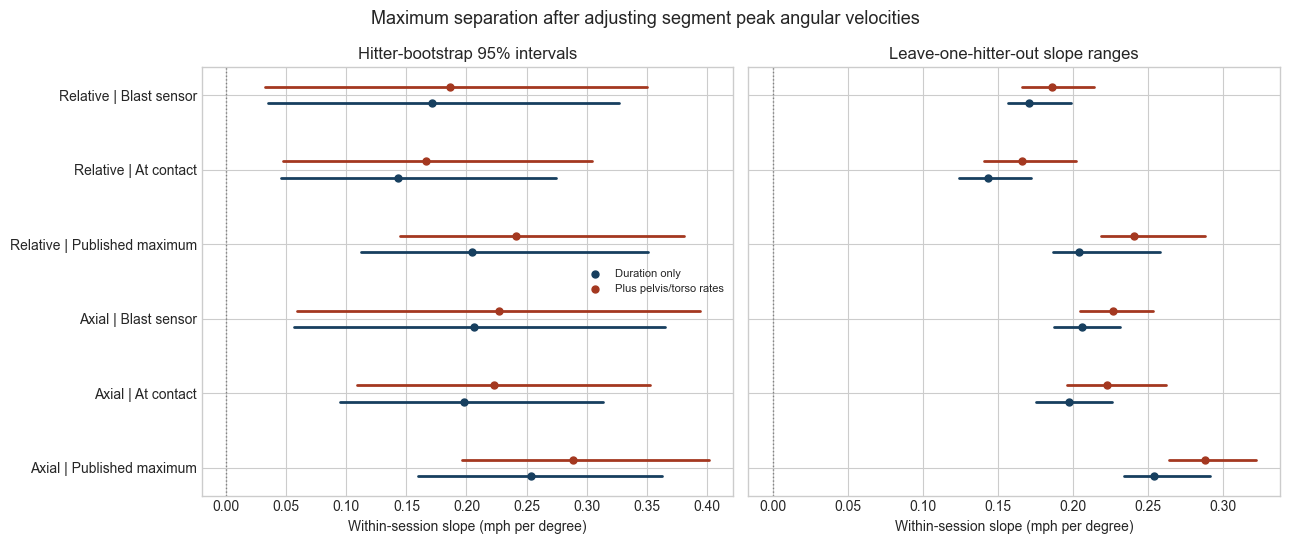

On the matched cohort, positive maximum-separation associations remain for published maximum and Blast speed under both definitions after conditioning on pelvis/torso peak angular velocities. This conditional within-session analysis does not establish causal effects or improve the earlier held-out prediction results.
Numerical checks passed: complete matched cohort, full-rank designs, sufficient-statistic coefficients equal direct WLS, and omission coefficients equal direct refits.


In [8]:
display(HTML('<h2>7. Adjustment for pelvis and torso rotation rates</h2>'))
VELOCITY_AUDIT_SEED = 20261029
velocity_shared = shared.merge(measurements[['session_swing']+PEAKS],on='session_swing',how='left',validate='one_to_one')
velocity_shared = velocity_shared.replace([np.inf,-np.inf],np.nan).dropna(subset=PEAKS).copy()
velocity_shared = velocity_shared[velocity_shared.groupby(GROUP).session_swing.transform('size')>=3].reset_index(drop=True)
velocity_users = np.array(sorted(velocity_shared.user.unique()))
if len(velocity_users)<15:
    raise ValueError('Insufficient complete hitters for velocity adjustment')
velocity_shared.to_csv(OUT/'velocity_adjustment_matched_swings.csv',index=False)
velocity_cohort = pd.DataFrame([{'stage':'previous matched cohort','swings':len(shared),'hitters':shared.user.nunique()},
    {'stage':'complete segment rates and at least three session-side swings','swings':len(velocity_shared),'hitters':len(velocity_users)}])
velocity_cohort.to_csv(OUT/'velocity_adjustment_cohort.csv',index=False)
velocity_counts = np.random.default_rng(VELOCITY_AUDIT_SEED).multinomial(len(velocity_users),np.full(len(velocity_users),1/len(velocity_users)),size=AUDIT_BOOTSTRAPS)

def velocity_design(d,feature,target,adjusted):
    predictors = [feature,'plant_to_contact_ms']+(PEAKS if adjusted else [])
    z = d[predictors+[target]]-d.groupby(GROUP)[predictors+[target]].transform('mean')
    scales = np.array([1.,100.]+([1000.,1000.] if adjusted else []))
    x = z[predictors].to_numpy(float)/scales
    y = z[target].to_numpy(float)
    aa,bb = [],[]
    for uid in velocity_users:
        mask = d.user.eq(uid).to_numpy()
        xi,yi = x[mask],y[mask]
        aa.append(xi.T@xi/len(xi))
        bb.append(xi.T@yi/len(xi))
    return np.array(aa),np.array(bb),x,y

velocity_rows,velocity_omissions,velocity_boots,velocity_design_rows = [],[],{},[]
for metric in AUDIT_METRICS:
    for definition in ['axial','relative']:
        feature = definition+'_'+metric
        for outcome,target in TARGETS.items():
            for model,adjusted in [('duration_only',False),('duration_plus_segment_rates',True)]:
                aa,bb,x,y = velocity_design(velocity_shared,feature,target,adjusted)
                summed_a,summed_b = aa.sum(axis=0),bb.sum(axis=0)
                if np.linalg.matrix_rank(summed_a)<x.shape[1]:
                    raise ValueError('Rank-deficient velocity-adjusted design')
                fit = sm.WLS(y,x,weights=weights(velocity_shared)).fit(cov_type='cluster',cov_kwds={'groups':velocity_shared.user},use_t=True)
                coef = np.linalg.solve(summed_a,summed_b)
                np.testing.assert_allclose(coef,fit.params,rtol=1e-7,atol=1e-8)
                ba = np.einsum('bh,hij->bij',velocity_counts,aa)
                by = velocity_counts@bb
                boot = np.linalg.solve(ba,by[...,None])[...,0][:,0]
                key = (metric,definition,outcome,model)
                velocity_boots[key] = boot
                lo,hi = np.quantile(boot,[.025,.975])
                omitted = []
                for i,uid in enumerate(velocity_users):
                    slope = np.linalg.solve(summed_a-aa[i],summed_b-bb[i])[0]
                    omitted.append(slope)
                    velocity_omissions.append({'metric':metric,'definition':definition,'outcome':outcome,'model':model,
                        'omitted_hitter':uid,'slope_mph_per_degree':slope,'change_from_full':slope-coef[0]})
                omitted = np.array(omitted)
                k = int(np.argmax(abs(omitted-coef[0])))
                velocity_rows.append({'metric':metric,'definition':definition,'outcome':outcome,'model':model,
                    'swings':len(velocity_shared),'hitters':len(velocity_users),'slope_mph_per_degree':coef[0],
                    'bootstrap_ci_low':lo,'bootstrap_ci_high':hi,'cluster_p':fit.pvalues[0],
                    'omission_min':omitted.min(),'omission_max':omitted.max(),
                    'omission_sign_reversals':int(np.sum(np.sign(omitted)!=np.sign(coef[0]))),
                    'largest_influence_hitter':velocity_users[k],'largest_absolute_slope_change':abs(omitted[k]-coef[0])})
                w = weights(velocity_shared)
                nuisance = x[:,1:]
                nuisance_coef = np.linalg.lstsq(nuisance*np.sqrt(w[:,None]),x[:,0]*np.sqrt(w),rcond=None)[0]
                residual = x[:,0]-nuisance@nuisance_coef
                remaining_fraction = np.sum(w*residual**2)/np.sum(w*x[:,0]**2)
                velocity_design_rows.append({'metric':metric,'definition':definition,'outcome':outcome,'model':model,
                    'scaled_design_condition_number':np.linalg.cond(np.sqrt(w[:,None])*x),
                    'separation_variance_remaining_fraction':remaining_fraction,'separation_vif':1/remaining_fraction})
                d = velocity_shared[velocity_shared.user.ne(velocity_users[0])].copy()
                predictors = [feature,'plant_to_contact_ms']+(PEAKS if adjusted else [])
                z = d[predictors+[target]]-d.groupby(GROUP)[predictors+[target]].transform('mean')
                scales = np.array([1.,100.]+([1000.,1000.] if adjusted else []))
                direct = sm.WLS(z[target],z[predictors].to_numpy()/scales,weights=weights(d)).fit().params.iloc[0]
                np.testing.assert_allclose(direct,np.linalg.solve(summed_a-aa[0],summed_b-bb[0])[0],rtol=1e-7,atol=1e-8)
velocity_adjustment = pd.DataFrame(velocity_rows)
velocity_adjustment['fdr_q'] = np.nan
for _,ix in velocity_adjustment.groupby(['metric','model']).groups.items():
    velocity_adjustment.loc[ix,'fdr_q'] = multipletests(velocity_adjustment.loc[ix,'cluster_p'],method='fdr_bh')[1]
velocity_changes = []
for metric in AUDIT_METRICS:
    for definition in ['axial','relative']:
        for outcome in TARGETS:
            index = (velocity_adjustment.metric==metric)&(velocity_adjustment.definition==definition)&(velocity_adjustment.outcome==outcome)
            rows = velocity_adjustment[index].set_index('model')
            delta = velocity_boots[(metric,definition,outcome,'duration_plus_segment_rates')]-velocity_boots[(metric,definition,outcome,'duration_only')]
            lo,hi = np.quantile(delta,[.025,.975])
            velocity_changes.append({'metric':metric,'definition':definition,'outcome':outcome,
                'adjusted_minus_duration_only_slope':rows.loc['duration_plus_segment_rates','slope_mph_per_degree']-rows.loc['duration_only','slope_mph_per_degree'],
                'paired_bootstrap_ci_low':lo,'paired_bootstrap_ci_high':hi})
velocity_slope_changes = pd.DataFrame(velocity_changes)
velocity_adjustment.to_csv(OUT/'velocity_adjusted_within_session_slopes.csv',index=False)
pd.DataFrame(velocity_omissions).to_csv(OUT/'velocity_adjusted_hitter_omissions.csv',index=False)
pd.DataFrame(velocity_design_rows).to_csv(OUT/'velocity_adjustment_design_audit.csv',index=False)
velocity_slope_changes.to_csv(OUT/'velocity_adjustment_paired_slope_changes.csv',index=False)
np.savez_compressed(OUT/'velocity_adjustment_paired_bootstrap.npz',**{'__'.join(k):v for k,v in velocity_boots.items()})
display(velocity_cohort)
display(velocity_adjustment[(velocity_adjustment.metric=='max_separation_deg')&(velocity_adjustment.model=='duration_plus_segment_rates')][['definition','outcome','slope_mph_per_degree','bootstrap_ci_low','bootstrap_ci_high','fdr_q','omission_sign_reversals']].round(4))
display(velocity_slope_changes[velocity_slope_changes.metric=='max_separation_deg'].round(4))
print('Matched comparison: separation + duration versus separation + duration + pelvis peak rate + torso peak rate.')
print('All variables are centered within hitter/session/side, with equal hitter weights. Slope units remain mph per degree.')
print('Bootstrap samples refit both models on the same resampled hitters. Omission ranges refit after removing each hitter.')
print('FDR covers six tests within each metric/model family; paired slope-change intervals are exploratory.')
print('Segment rates are contemporaneous motion measurements. Conditioning on them changes the association being estimated; this is not causal mediation or proof of a mechanism.')
fig,axes = plt.subplots(1,2,figsize=(13,5.5),sharey=True)
primary = velocity_adjustment[velocity_adjustment.metric=='max_separation_deg']
order = [(d,o) for d in ['axial','relative'] for o in TARGETS]
for i,(definition,outcome) in enumerate(order):
    for model,offset,color in [('duration_only',-.11,'#173f5f'),('duration_plus_segment_rates',.11,'#a43820')]:
        row = primary[(primary.definition==definition)&(primary.outcome==outcome)&(primary.model==model)].iloc[0]
        label = 'Duration only' if model=='duration_only' else 'Plus pelvis/torso rates'
        axes[0].plot([row.bootstrap_ci_low,row.bootstrap_ci_high],[i+offset,i+offset],color=color,lw=2)
        axes[0].scatter(row.slope_mph_per_degree,i+offset,color=color,s=25,label=label if i==0 else None)
        axes[1].plot([row.omission_min,row.omission_max],[i+offset,i+offset],color=color,lw=2)
        axes[1].scatter(row.slope_mph_per_degree,i+offset,color=color,s=25)
axes[0].set_yticks(np.arange(len(order)),[d.title()+' | '+labels[o] for d,o in order])
axes[0].set_title('Hitter-bootstrap 95% intervals')
axes[1].set_title('Leave-one-hitter-out slope ranges')
for ax in axes:
    ax.axvline(0,color='gray',ls=':',lw=1)
    ax.set_xlabel('Within-session slope (mph per degree)')
axes[0].legend(fontsize=8)
fig.suptitle('Maximum separation after adjusting segment peak angular velocities',fontsize=13)
fig.tight_layout()
fig.savefig(FIG/'velocity_adjusted_magnitude.png',dpi=160)
plt.show()
main_adjusted = primary[(primary.model=='duration_plus_segment_rates')&primary.outcome.isin(['peak_speed','blast_speed'])]
if (main_adjusted.bootstrap_ci_low>0).all():
    velocity_message = 'On the matched cohort, positive maximum-separation associations remain for published maximum and Blast speed under both definitions after conditioning on pelvis/torso peak angular velocities.'
elif (main_adjusted.bootstrap_ci_high<0).all():
    velocity_message = 'On the matched cohort, all four adjusted maximum-separation associations are negative with hitter-bootstrap intervals below zero.'
else:
    velocity_message = 'After conditioning on pelvis/torso peak angular velocities, the maximum-separation association is not uniformly supported across both definitions and published maximum/Blast speed.'
velocity_message += ' This conditional within-session analysis does not establish causal effects or improve the earlier held-out prediction results.'
print(velocity_message)
(OUT/'velocity_adjustment_summary.txt').write_text(velocity_message)
print('Numerical checks passed: complete matched cohort, full-rank designs, sufficient-statistic coefficients equal direct WLS, and omission coefficients equal direct refits.')

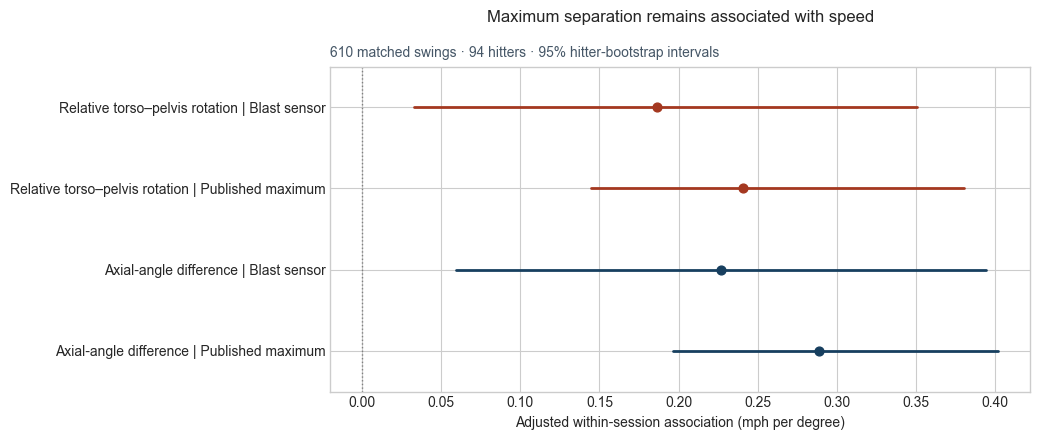

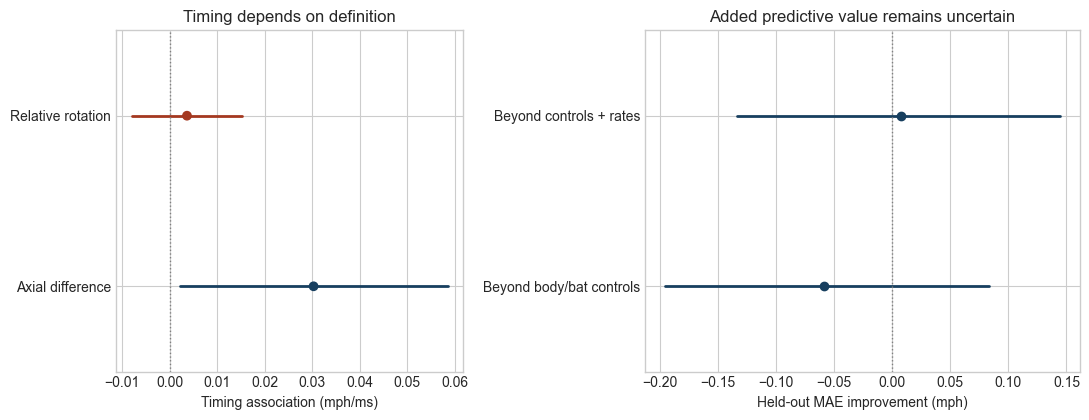

Final summary, figures, supporting tables and reproducibility manifest saved. No additional models were introduced.


In [9]:
display(HTML('<h2>8. Final evidence summary</h2>'))
peak_comparison = comparisons[(comparisons.outcome=='peak_speed')&(comparisons.baseline=='controls')&(comparisons.added=='combined')].iloc[0]
selected_primary = velocity_adjustment[(velocity_adjustment.metric=='max_separation_deg')&(velocity_adjustment.model=='duration_plus_segment_rates')&velocity_adjustment.outcome.isin(['peak_speed','blast_speed'])].copy()
selected_primary['Definition'] = selected_primary.definition.map({'axial':'Axial-angle difference','relative':'Relative torso–pelvis rotation'})
selected_primary['Speed measurement'] = selected_primary.outcome.map({'peak_speed':'Published maximum','blast_speed':'Blast sensor'})
selected_primary['Slope (mph/degree)'] = selected_primary.slope_mph_per_degree.map(lambda v:f'{v:+.3f}')
selected_primary['95% hitter-bootstrap interval'] = selected_primary.apply(lambda r:f'{r.bootstrap_ci_low:+.3f} to {r.bootstrap_ci_high:+.3f}',axis=1)
selected_primary['FDR q'] = selected_primary.fdr_q.map(lambda v:'<0.001' if v<.001 else f'{v:.3f}')
selected_primary['Omission sign reversals'] = selected_primary.omission_sign_reversals
final_magnitude_table = selected_primary[['Definition','Speed measurement','Slope (mph/degree)','95% hitter-bootstrap interval','FDR q','Omission sign reversals']]
primary_models = model_summary[model_summary.outcome=='peak_speed'].set_index('model')
summary_models = pd.DataFrame([{'Model':'Body/bat controls','Held-out MAE (mph)':primary_models.loc['controls','hitter_mae_mph']},
    {'Model':'Controls + separation magnitude and timing','Held-out MAE (mph)':primary_models.loc['combined','hitter_mae_mph']},
    {'Model':'Controls + segment peak rates','Held-out MAE (mph)':primary_models.loc['controls_rotation','hitter_mae_mph']},
    {'Model':'Controls + rates + magnitude and timing','Held-out MAE (mph)':primary_models.loc['combined_rotation','hitter_mae_mph']}])
timing_native = sensitivity[(sensitivity.setting=='native')&(sensitivity.feature=='peak_separation_ms_before_contact')].iloc[0]
timing_relative = sensitivity[(sensitivity.setting=='relative_rotation')&(sensitivity.feature=='peak_separation_ms_before_contact')].iloc[0]
final_timing_table = pd.DataFrame([{'Definition':'Axial-angle difference','Slope (mph/ms)':timing_native.within_alternate_slope,'95% hitter-clustered interval':f'{timing_native.within_alternate_ci_low:+.3f} to {timing_native.within_alternate_ci_high:+.3f}'},
    {'Definition':'Relative torso–pelvis rotation','Slope (mph/ms)':timing_relative.within_alternate_slope,'95% hitter-clustered interval':f'{timing_relative.within_alternate_ci_low:+.3f} to {timing_relative.within_alternate_ci_high:+.3f}'}])
matched_n,matched_h = len(velocity_shared),velocity_shared.user.nunique()
positive = bool((selected_primary.bootstrap_ci_low>0).all())
if positive:
    magnitude_conclusion = 'Greater maximum separation was associated with higher bat speed within sessions across both separation definitions and both primary speed measurements, including after adjustment for pelvis and torso peak angular velocities.'
else:
    magnitude_conclusion = 'Maximum-separation associations were not consistently supported across both separation definitions and speed measurements after segment-rate adjustment.'
if peak_comparison.ci_low<=0<=peak_comparison.ci_high:
    prediction_conclusion = 'Adding separation magnitude and timing did not clearly improve prediction for held-out hitters.'
elif peak_comparison.ci_low>0:
    prediction_conclusion = 'Adding separation magnitude and timing improved held-out prediction within this dataset.'
else:
    prediction_conclusion = 'The combined separation model performed worse than controls in held-out prediction within this dataset.'
timing_conclusion = 'The timing result depends on how separation is defined. An earlier maximum has a positive within-session estimate for the axial-angle difference, but the relative-rotation interval includes zero; a general timing target is not established.'
variance_caveat = 'The adjusted associations condition on contemporaneous segment peak rates. They are not a mediation analysis or evidence of a causal mechanism.'
notes = [
    f'The main motion cohort contains {len(measurements)} swings from {measurements.user.nunique()} hitters. The matched sensor/definition/velocity audit contains {matched_n} swings from {matched_h} hitters. Primary prediction uses '+str(int(pd.DataFrame(cohorts).set_index('outcome').loc['peak_speed','swings']))+' swings; different tables answer different questions on their stated cohorts.',
    'Primary separation is pelvis minus torso processed axial angle. Relative torso–pelvis rotation is a separate definition. Neither is a direct measurement of muscle stretch, stored energy or force transfer.',
    'Within-session regressions center variables within hitter/session/side, require at least three complete swings, and weight hitters equally. Main adjusted slopes condition on duration and both segment peak rates. They do not describe differences between athletes.',
    'Magnitude intervals resample whole hitters and refit regressions. Timing intervals use hitter-clustered covariance. The FDR correction covers six tests per metric/model family; exploratory comparisons across the broader study are not covered by one global correction.',
    'Prediction holds out whole hitters, with scaling and ridge tuning inside training folds. Its conditional bootstrap intervals resample fixed held-out errors and do not rerun model fitting.',
    'The primary outcome is OBP’s published maximum resultant bat speed. Its exact maximum-search interval is not independently reconstructed. Contact speed and Blast speed are distinct measurements.',
    'Short sessions, restricted athlete coverage, measurement error and unmeasured pitch/impact context limit interpretation. Individual omission stability does not establish test–retest reliability, external validity or a coaching response.'
]
practical = 'Use separation magnitude as a descriptive feature for reviewing a hitter’s swings alongside rotation rates and context. These data do not justify prescribing extra separation, a universal angle, a timing target or an expected mph gain.'
headline = 'A consistent within-session magnitude association; timing and predictive value remain limited' if positive else 'Mixed evidence across definitions, sensors and prediction'
style = '<style>.study20{font:15px/1.55 system-ui;color:#182a36;max-width:1100px}.study20 h1{font-size:29px;line-height:1.15}.study20 h2{font-size:20px;margin-top:28px}.study20 .lead{font-size:18px}.study20 .band{background:#eef3f7;padding:16px 20px;border-left:4px solid #173f5f;margin:18px 0}.study20 table{border-collapse:collapse;display:block;overflow-x:auto;max-width:100%;font-size:13px}.study20 th,.study20 td{padding:9px 11px;text-align:left;border-bottom:1px solid #d6dfe6}.study20 th{background:#edf2f5}.study20 img{max-width:100%}.study20 details{margin:15px 0}.study20 summary{cursor:pointer;font-weight:600}.study20 .small{font-size:13px;color:#465767}</style>'
summary_html = style+'<div class="study20"><h1>Pelvis–Torso Separation & Bat Speed</h1><p class="lead">'+html.escape(headline)+'</p>'
summary_html += '<div class="band"><b>Main finding</b><p>'+html.escape(magnitude_conclusion)+'</p><p>'+html.escape(prediction_conclusion)+'</p></div>'
summary_html += '<h2>1. Magnitude: the most consistent association</h2><p>Same '+str(matched_n)+' swings from '+str(matched_h)+' hitters for every row. Slopes adjust within-session duration and both segment peak angular velocities.</p>'+final_magnitude_table.to_html(index=False,escape=True)
summary_html += '<p>Intervals are hitter-bootstrap 95% intervals. Omission counts refer to coefficient direction, not whether every omitted-sample interval excludes zero. '+html.escape(variance_caveat)+'</p>'
summary_html += '<h2>2. Timing: sensitive to the definition</h2><p>'+html.escape(timing_conclusion)+'</p>'+final_timing_table.round({'Slope (mph/ms)':3}).to_html(index=False)+'<p class="small">Separate duration-adjusted associations with published maximum speed; positive means an earlier peak relative to contact. These are not the joint magnitude/timing model. The native separate timing test did not survive its five-test FDR family; the joint-model result remains exploratory and definition-specific.</p>'
summary_html += '<h2>3. Generalization: no clear added predictive value</h2>'+summary_models.round(3).to_html(index=False)
summary_html += '<p>Controls versus controls plus separation: paired MAE improvement '+f'{peak_comparison.mae_improvement_mph:+.3f}'+' mph, conditional 95% interval '+f'{peak_comparison.ci_low:+.3f} to {peak_comparison.ci_high:+.3f}'+'. Positive favors added features. '+html.escape(prediction_conclusion)+'</p>'
summary_html += '<h2>What this supports in player development</h2><p>'+html.escape(practical)+'</p>'
summary_html += '<h2>Scope and interpretation</h2><ul>'+''.join('<li>'+html.escape(t)+'</li>' for t in notes)+'</ul></div>'
final_magnitude_table.to_csv(OUT/'final_magnitude_summary.csv',index=False)
summary_models.to_csv(OUT/'final_prediction_summary.csv',index=False)
final_timing_table.to_csv(OUT/'final_timing_summary.csv',index=False)
(OUT/'final_conclusions.txt').write_text((chr(10)*2).join([magnitude_conclusion,timing_conclusion,prediction_conclusion,practical]+notes))
fig,ax = plt.subplots(figsize=(10.5,4.5))
q = selected_primary.reset_index(drop=True)
for i,row in q.iterrows():
    color = '#173f5f' if row.definition=='axial' else '#a43820'
    ax.plot([row.bootstrap_ci_low,row.bootstrap_ci_high],[i,i],color=color,lw=2)
    ax.scatter(row.slope_mph_per_degree,i,color=color,s=40,zorder=3)
ax.set_yticks(np.arange(len(q)),[r['Definition']+' | '+r['Speed measurement'] for _,r in q.iterrows()])
ax.axvline(0,color='gray',ls=':',lw=1)
ax.set_xlabel('Adjusted within-session association (mph per degree)')
ax.set_title('Maximum separation remains associated with speed',pad=32)
ax.set_ylim(-.5,len(q)-.5)
ax.text(0,1.03,f'{matched_n} matched swings · {matched_h} hitters · 95% hitter-bootstrap intervals',transform=ax.transAxes,fontsize=10,color='#465767')
fig.tight_layout()
fig.savefig(FIG/'final_magnitude_evidence.png',dpi=170,bbox_inches='tight')
plt.show()
fig,axes = plt.subplots(1,2,figsize=(11,4.3),gridspec_kw={'width_ratios':[1,1.25]})
axes[0].scatter(final_timing_table['Slope (mph/ms)'],np.arange(2),color=['#173f5f','#a43820'],zorder=3)
for i,r in enumerate([timing_native,timing_relative]):
    axes[0].plot([r.within_alternate_ci_low,r.within_alternate_ci_high],[i,i],color=['#173f5f','#a43820'][i],lw=2)
axes[0].set_yticks([0,1],['Axial difference','Relative rotation'])
axes[0].axvline(0,color='gray',ls=':',lw=1)
axes[0].set(xlabel='Timing association (mph/ms)',title='Timing depends on definition')
comp = comparisons[(comparisons.outcome=='peak_speed')&(((comparisons.baseline=='controls')&(comparisons.added=='combined'))|((comparisons.baseline=='controls_rotation')&(comparisons.added=='combined_rotation')))].copy().reset_index(drop=True)
for i,r in comp.iterrows():
    axes[1].plot([r.ci_low,r.ci_high],[i,i],color='#173f5f',lw=2)
    axes[1].scatter(r.mae_improvement_mph,i,color='#173f5f',zorder=3)
axes[1].set_yticks([0,1],['Beyond body/bat controls','Beyond controls + rates'])
for ax in axes:
    ax.set_ylim(-.5,1.5)
axes[1].axvline(0,color='gray',ls=':',lw=1)
axes[1].set(xlabel='Held-out MAE improvement (mph)',title='Added predictive value remains uncertain')
fig.tight_layout()
fig.savefig(FIG/'final_timing_prediction.png',dpi=170,bbox_inches='tight')
plt.show()
display(HTML(summary_html))

manifest = {'study':20,'velocity_audit_seed':VELOCITY_AUDIT_SEED,'velocity_audit_swings':len(velocity_shared),'velocity_audit_hitters':len(velocity_users),'robustness_seed':AUDIT_SEED,'robustness_bootstraps':AUDIT_BOOTSTRAPS,'robustness_matched_swings':len(shared),'robustness_matched_hitters':len(users),'primary_separation':'signed pelvis minus torso processed axial angles',
    'association_controls':INFERENCE_CONTROLS,'association_bat_weight_omitted_reason':'only two hitters have nonstandard bat drop; one remains in Blast cohort, giving unit leverage under full controls',
    'primary_outcome':'published bat_speed_mph_max_x; exact maximum search window unverified',
    'c3d_required':False,'seed_repeats':list(SEEDS),'alphas':list(ALPHAS),'bootstraps':BOOTSTRAPS,
    'inputs':{p.name:sha256(p) for p in [RAW/(n+'.csv') for n in ('joint_angles','joint_velos','metadata','poi_metrics')]},
    'settings':settings,'models':MODELS,'raw_swings':len(base),'retained_swings':len(measurements),
    'python':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','statsmodels','matplotlib']}}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))

manifest['presentation'] = 'consolidated final summary; original analyses retained'
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
import base64
report = '<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>Pelvis–Torso Separation & Bat Speed</title></head><body style="max-width:1100px;margin:36px auto;padding:0 24px">'+summary_html
for name in ['final_magnitude_evidence.png','final_timing_prediction.png']:
    p = FIG/name
    report += '<img style="max-width:100%" src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'">'
appendices = [
    ('Measurement conventions and design diagnostics',audit,pd.DataFrame(design_rows)),
    ('Separate and joint associations',associations,joint_associations),
    ('Held-out comparisons and cohorts',comparisons,pd.DataFrame(cohorts)),
    ('Measurement and model sensitivities',sensitivity,pd.DataFrame(refit_comparisons)),
    ('Matched sensor and definition audit',robustness,paired_slope_comparisons),
    ('Segment-rate adjustment and paired slope changes',velocity_adjustment,velocity_slope_changes),
    ('Velocity-adjustment collinearity diagnostics',pd.DataFrame(velocity_design_rows))
]
report += '<div class="study20"><h2>Supporting analyses</h2><p>These tables preserve the analysis details. Their cohorts and interval procedures differ as documented in the summary.</p>'
for title,*tables in appendices:
    report += '<details><summary>'+html.escape(title)+'</summary>'
    for table in tables:
        report += table.round(4).to_html(index=False)
    report += '</details>'
report += '<details><summary>Supporting figures</summary>'
for name in ['matched_magnitude_robustness.png','velocity_adjusted_magnitude.png']:
    p = FIG/name
    if p.exists():
        report += '<img style="max-width:100%" src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'">'
report += '</details></div></body></html>'
(OUT/'study_summary.html').write_text(report)
print('Final summary, figures, supporting tables and reproducibility manifest saved. No additional models were introduced.')